**Introducción a la Ciencia de Datos 2026**
Posgrado en Ciencias de la Computación - CICESE
Dr. Irvin Hussein López Nava

## ICD - 13: Árboles de decisión

Sesión 13 del curso. Diapositivas: [icd-13-arboles-decision.pdf](https://github.com/husseinlopez/icd2026/blob/main/clases/icd-13-arboles-decision.pdf)

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/husseinlopez/icd2026/blob/main/icd-13-arboles-decision.ipynb)

En la sesión 12 los clasificadores fueron cajas negras: los evaluamos sin abrirlos. Hoy abrimos el primero. En clase vimos cómo ID3 construye un árbol de arriba hacia abajo, eligiendo en cada nodo el atributo que más reduce la entropía. También vimos por qué un árbol que crece hasta clasificar bien todos los ejemplos se sobreajusta, cómo se poda, y lo que C4.5 agrega para atributos continuos, atributos con muchos valores y valores faltantes.

El notebook tiene cuatro partes. En la primera programamos ID3 y reproducimos, cifra por cifra, el ejemplo de *Play tennis* de las diapositivas. En la segunda lo rompemos a propósito, con un identificador y con atributos continuos. En la tercera pasamos los mismos días a scikit-learn, que no implementa ID3 ni C4.5 sino CART. En la cuarta volvemos al vino de la sesión 12 para decidir cuánto podar con validación; es el protocolo que usaremos en las sesiones 14 a 16 y en la práctica de la unidad.

---

### Preparación

Las bibliotecas de siempre. Las secciones 1 y 2 solo usan pandas y la biblioteca estándar de Python; scikit-learn entra en la sección 3.

In [1]:
import math
from collections import Counter
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("matplotlib  ", __import__("matplotlib").__version__)
print("scikit-learn", sklearn.__version__)

numpy        2.5.3
pandas       3.0.5
matplotlib   3.11.2
scikit-learn 1.9.1


Paleta y estilo de las sesiones anteriores. El naranja sigue siendo lo que produce el modelo.

In [2]:
AZUL_OSCURO = "#112057"
AZUL = "#7697CD"
AZUL_MEDIO = "#3C51A9"
NARANJA = "#E76A28"      # lo que produce el modelo
GRIS = "#5B6584"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlecolor": AZUL_OSCURO,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelcolor": AZUL_OSCURO,
    "axes.edgecolor": "#C9CFDF",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#E3E6EF",
    "xtick.color": GRIS,
    "ytick.color": GRIS,
    "legend.frameon": False,
})

SEMILLA = 42                        # fija las particiones para que los resultados se repitan
CLASES = ["baja", "media", "alta"]  # el orden en que se muestran las clases del vino

---

### Los datos

Dos versiones de los mismos 14 días de *Play tennis* (Quinlan, 1986; Mitchell, 1997, tabla 3.2), y el vino de la sesión 12:

- `weather.nominal.csv` es la tabla de la lámina 20: cuatro atributos con valores discretos. Es nuevo en el repositorio.
- `weather.numeric.csv` es la de la sesión 2: los mismos días y la misma clase, pero con la temperatura y la humedad medidas.
- `vinos-3clases.csv` es el vino de 3 clases de la sesión 12. Lo usamos en la sección 4.

En las tres lecturas, la primera línea funciona tal cual desde la carpeta del repositorio clonado. En Colab, comenta la primera y descomenta la segunda.

In [3]:
nominal = pd.read_csv("datos/weather.nominal.csv")
# nominal = pd.read_csv("https://raw.githubusercontent.com/husseinlopez/icd2026/main/datos/weather.nominal.csv")

numerico = pd.read_csv("datos/weather.numeric.csv")
# numerico = pd.read_csv("https://raw.githubusercontent.com/husseinlopez/icd2026/main/datos/weather.numeric.csv")

nominal

,Day,Outlook,Temperature,Humidity,Wind,Play
0,1,sunny,hot,high,weak,False
1,2,sunny,hot,high,strong,False
2,3,overcast,hot,high,weak,True
3,4,rain,mild,high,weak,True
4,5,rain,cool,normal,weak,True
5,6,rain,cool,normal,strong,False
6,7,overcast,cool,normal,strong,True
7,8,sunny,mild,high,weak,False
8,9,sunny,cool,normal,weak,True
9,10,rain,mild,normal,weak,True


**Lectura.** `Play` vale `True` en 9 días y `False` en 5: es el [9+, 5−] de las diapositivas, donde `True` es Yes. `Day` es el número de día. Es un identificador, no una medición (sesión 2), pero lo dejamos en la tabla a propósito: la sección 2 muestra qué pasa si se cuela como atributo.

Las dos versiones describen los mismos días, y los cortes de la lámina 45 convierten una en la otra:

In [4]:
mismos = ["Day", "Outlook", "Wind", "Play"]
print("Mismos días, perspectiva, viento y clase:", (nominal[mismos] == numerico[mismos]).all().all())

temperatura = pd.cut(numerico["Temperature"], bins=[0, 69, 76, 100], labels=["cool", "mild", "hot"])
humedad = np.where(numerico["Humidity"] > 82, "high", "normal")
print("Temperatura discretizada = nominal:", (temperatura.astype(str) == nominal["Temperature"]).all())
print("Humedad discretizada = nominal:    ", (humedad == nominal["Humidity"]).all())

Mismos días, perspectiva, viento y clase: True
Temperatura discretizada = nominal: True
Humedad discretizada = nominal:     True


---

## 1. *Play tennis* a mano

ID3 necesita dos medidas: la **entropía** de un conjunto de ejemplos (láminas 15 a 18) y la **ganancia de información** de un atributo (lámina 19). Las dos caben en unas líneas de Python.

In [5]:
def entropia(clases):
    # Entropía de una colección de clases (lámina 16): la suma de −p·log2(p) sobre las clases presentes.
    # Una clase ausente no aparece en el conteo, así que 0·log2(0) nunca se calcula: vale 0 por convención.
    n = len(clases)
    return sum(-c / n * math.log2(c / n) for c in Counter(clases).values())


print(f"Entropy([9+, 5−])  = {entropia(nominal['Play']):.3f}")
print(f"Entropy([7+, 7−])  = {entropia([True] * 7 + [False] * 7):.3f}")
print(f"Entropy([14+, 0−]) = {entropia([True] * 14):.3f}")

Entropy([9+, 5−])  = 0.940
Entropy([7+, 7−])  = 1.000
Entropy([14+, 0−]) = 0.000


**Lectura.** Son los tres casos de las láminas 17 y 18: 0.940 para los 14 días, 1 cuando las dos clases están empatadas y 0 cuando el conjunto es puro.

In [6]:
def ganancia(datos, atributo, objetivo="Play"):
    # Ganancia de información (lámina 19): la entropía antes de partir, menos el promedio
    # de la entropía de las partes, ponderado por su tamaño.
    n = len(datos)
    despues = sum(len(parte) / n * entropia(parte[objetivo]) for _, parte in datos.groupby(atributo))
    return entropia(datos[objetivo]) - despues


ATRIBUTOS = ["Outlook", "Temperature", "Humidity", "Wind"]

pd.Series({a: ganancia(nominal, a) for a in ATRIBUTOS}, name="Gain(S, A)").sort_values(ascending=False).round(3).to_frame()

,"Gain(S, A)"
Outlook,0.247
Humidity,0.152
Wind,0.048
Temperature,0.029


**Lectura.** Outlook gana con 0.247 y va en la raíz (lámina 22). Humidity da 0.152, no el 0.151 de la lámina 21: Mitchell redondea las entropías intermedias a tres decimales antes de restar. Aquí no se redondea nada hasta el final.

Debajo de la raíz se repite la cuenta con los días de cada rama:

In [7]:
for rama in ["sunny", "rain"]:
    parte = nominal[nominal["Outlook"] == rama]
    print(f"Outlook = {rama}: días {parte['Day'].tolist()}, Entropy = {entropia(parte['Play']):.3f}")
    for a in ["Temperature", "Humidity", "Wind"]:
        print(f"    Gain(S_{rama}, {a}) = {ganancia(parte, a):.3f}")

Outlook = sunny: días [1, 2, 8, 9, 11], Entropy = 0.971
    Gain(S_sunny, Temperature) = 0.571
    Gain(S_sunny, Humidity) = 0.971
    Gain(S_sunny, Wind) = 0.020
Outlook = rain: días [4, 5, 6, 10, 14], Entropy = 0.971
    Gain(S_rain, Temperature) = 0.020
    Gain(S_rain, Humidity) = 0.020
    Gain(S_rain, Wind) = 0.971


**Lectura.** En la rama Sunny gana Humidity, y en la rama Rain, Wind; las dos con 0.971, porque separan su rama por completo. Son las cifras de las láminas 25 a 27.

### El algoritmo

Con esas dos funciones, ID3 es el pseudocódigo de la lámina 28 casi línea por línea. El árbol se guarda como diccionarios anidados: un nodo interno tiene un `atributo` y una rama por valor; una hoja tiene una clase y el conteo de ejemplos que llegaron a ella.

In [8]:
def id3(datos, atributos, objetivo="Play", criterio=ganancia, valores=None):
    # ID3 (lámina 28). `valores` guarda todos los valores posibles de cada atributo,
    # para crear también las ramas que en un subconjunto quedan vacías.
    if valores is None:
        valores = {a: sorted(datos[a].unique()) for a in atributos}
    clases = datos[objetivo]
    conteo = {True: int(clases.sum()), False: int((~clases).sum())}
    mayoritaria = conteo[True] >= conteo[False]

    if clases.nunique() == 1 or not atributos:        # nodo puro, o ya no hay atributos: hoja
        return {"clase": mayoritaria, "conteo": conteo}

    mejor = max(atributos, key=lambda a: criterio(datos, a, objetivo))   # en un empate, el primero
    resto = [a for a in atributos if a != mejor]
    ramas = {}
    for v in valores[mejor]:
        parte = datos[datos[mejor] == v]
        if len(parte) == 0:                            # rama vacía: la clase mayoritaria del nodo
            ramas[v] = {"clase": mayoritaria, "conteo": {True: 0, False: 0}}
        else:
            ramas[v] = id3(parte, resto, objetivo, criterio, valores)
    return {"atributo": mejor, "ramas": ramas, "clase": mayoritaria, "conteo": conteo}


def mostrar(nodo, sangria=""):
    # Imprime el árbol como export_text de scikit-learn, con el conteo [positivos+, negativos−] de cada hoja.
    for valor, hijo in nodo["ramas"].items():
        if "atributo" in hijo:
            print(f"{sangria}{nodo['atributo']} = {valor}")
            mostrar(hijo, sangria + "|   ")
        else:
            c = hijo["conteo"]
            print(f"{sangria}{nodo['atributo']} = {valor}: {hijo['clase']}  [{c[True]}+, {c[False]}−]")


def predecir(nodo, ejemplo):
    # Baja por el árbol siguiendo los valores del ejemplo. Si llega a un valor que el árbol
    # nunca vio, responde con la clase mayoritaria del nodo donde se quedó.
    while "atributo" in nodo:
        valor = ejemplo[nodo["atributo"]]
        if valor not in nodo["ramas"]:
            return nodo["clase"]
        nodo = nodo["ramas"][valor]
    return nodo["clase"]


def hojas(nodo):
    return 1 if "atributo" not in nodo else sum(hojas(h) for h in nodo["ramas"].values())

In [9]:
arbol = id3(nominal, ATRIBUTOS)
mostrar(arbol)
print(f"\nHojas: {hojas(arbol)}")

Outlook = overcast: True  [4+, 0−]
Outlook = rain
|   Wind = strong: False  [0+, 2−]
|   Wind = weak: True  [3+, 0−]
Outlook = sunny
|   Humidity = high: False  [0+, 3−]
|   Humidity = normal: True  [2+, 0−]

Hojas: 5


**Lectura.** Es el árbol de la lámina 8: Outlook en la raíz, Humidity bajo Sunny, Wind bajo Rain, y cinco hojas puras. ID3 se detuvo porque ya no quedaba ningún nodo con días de las dos clases.

In [10]:
aciertos = sum(predecir(arbol, dia) == dia["Play"] for _, dia in nominal.iterrows())
print(f"Aciertos en los 14 días de entrenamiento: {aciertos} de {len(nominal)}")

nuevo = {"Outlook": "sunny", "Temperature": "hot", "Humidity": "normal", "Wind": "strong"}
print(f"Un día soleado, caluroso, de humedad normal y con viento fuerte: Play = {predecir(arbol, nuevo)}")

Aciertos en los 14 días de entrenamiento: 14 de 14
Un día soleado, caluroso, de humedad normal y con viento fuerte: Play = True


**Lectura.** El árbol clasifica bien los 14 días con que se construyó, y eso no dice nada sobre días nuevos (sesión 12). El día de la segunda línea no está en la tabla: el árbol lo manda por Sunny y Normal, y responde que sí se juega.

### El ejemplo 15

La lámina 33 agrega ese mismo día con la etiqueta equivocada, `Play = False`, y pregunta qué le pasa al árbol.

In [11]:
ruidoso = pd.DataFrame([{"Day": 15, **nuevo, "Play": False}])
con_ruido = pd.concat([nominal, ruidoso], ignore_index=True)

arbol_ruido = id3(con_ruido, ATRIBUTOS)
mostrar(arbol_ruido)
print(f"\nHojas: {hojas(arbol)} sin el día 15; {hojas(arbol_ruido)} con él")

Outlook = overcast: True  [4+, 0−]
Outlook = rain
|   Wind = strong: False  [0+, 2−]
|   Wind = weak: True  [3+, 0−]
Outlook = sunny
|   Temperature = cool: True  [1+, 0−]
|   Temperature = hot: False  [0+, 3−]
|   Temperature = mild
|   |   Humidity = high: False  [0+, 1−]
|   |   Humidity = normal: True  [1+, 0−]

Hojas: 5 sin el día 15; 7 con él


In [12]:
print(f"Gain(S, Outlook) con el día 15 = {ganancia(con_ruido, 'Outlook'):.3f}")
sunny = con_ruido[con_ruido["Outlook"] == "sunny"]
print(f"Outlook = sunny con el día 15: Entropy = {entropia(sunny['Play']):.3f}")
for a in ["Temperature", "Humidity", "Wind"]:
    print(f"    Gain(S_sunny, {a}) = {ganancia(sunny, a):.3f}")

Gain(S, Outlook) con el día 15 = 0.280
Outlook = sunny con el día 15: Entropy = 0.918
    Gain(S_sunny, Temperature) = 0.585
    Gain(S_sunny, Humidity) = 0.459
    Gain(S_sunny, Wind) = 0.000


**Lectura.** No basta con colgar un nodo nuevo debajo de Normal. ID3 recalcula todo: la raíz sigue siendo Outlook, pero en la rama Sunny, que ahora tiene [2+, 4−], Temperature (0.585) le gana a Humidity (0.459). Bajo Mild, Humidity y Wind empatan con 1.0, y `max` se queda con el primero de la lista. El árbol pasa de 5 a 7 hojas (lámina 34).

¿Cuánto cambian sus predicciones? Hay 3 × 3 × 2 × 2 = 36 combinaciones posibles de los cuatro atributos:

In [13]:
valores = [sorted(nominal[a].unique()) for a in ATRIBUTOS]
combinaciones = [dict(zip(ATRIBUTOS, c)) for c in product(*valores)]
cambian = [c for c in combinaciones if predecir(arbol, c) != predecir(arbol_ruido, c)]

print(f"{len(cambian)} de las {len(combinaciones)} combinaciones cambian de clase:")
pd.DataFrame(cambian).assign(antes=[predecir(arbol, c) for c in cambian],
                             después=[predecir(arbol_ruido, c) for c in cambian])

4 de las 36 combinaciones cambian de clase:


,Outlook,Temperature,Humidity,Wind,antes,después
0,sunny,cool,high,strong,False,True
1,sunny,cool,high,weak,False,True
2,sunny,hot,normal,strong,True,False
3,sunny,hot,normal,weak,True,False


**Lectura.** Un solo ejemplo mal etiquetado cambia la clase de 4 combinaciones. Una es el propio día 15; las otras tres no aparecen en ninguno de los 15 días. Por ejemplo, un día soleado, fresco y húmedo era No y ahora es Yes, sin que ningún día nuevo lo respalde. Es el sobreajuste de la lámina 35: para acertar los 15 días de entrenamiento, el árbol cambió sus predicciones en zonas donde no tenía datos.

---

## 2. Donde ID3 se rompe

### Un identificador como atributo

El recuadro «Attributes» de la lámina 20 incluye `day`. Si se lo damos a ID3 como un atributo más:

In [14]:
print(f"Gain(S, Day) = {ganancia(nominal, 'Day'):.3f}")

arbol_dia = id3(nominal, ["Day"] + ATRIBUTOS)
print(f"Raíz: {arbol_dia['atributo']}, con {len(arbol_dia['ramas'])} ramas y {hojas(arbol_dia)} hojas")

dia_15 = {"Day": 15, "Outlook": "sunny", "Temperature": "hot", "Humidity": "high", "Wind": "weak"}
print(f"Día 15, soleado, caluroso, húmedo y sin viento: Play = {predecir(arbol_dia, dia_15)}")
print(f"El mismo día con el árbol sin Day:              Play = {predecir(arbol, dia_15)}")

Gain(S, Day) = 0.940
Raíz: Day, con 14 ramas y 14 hojas
Día 15, soleado, caluroso, húmedo y sin viento: Play = True
El mismo día con el árbol sin Day:              Play = False


**Lectura.** Day tiene la ganancia más alta posible, 0.940: cada día es una rama pura. El árbol resultante memoriza la tabla y no sirve para nada más. El día 15 no tiene rama, así que el árbol responde con la clase mayoritaria de la raíz, Yes, haga el clima que haga. El árbol sin Day dice No, como en D1, que tenía ese mismo clima.

### ¿Lo arregla GainRatio?

La lámina 46 propone dividir la ganancia entre la **información de partición**, que crece con el número de ramas. Es la entropía de los valores del atributo, sin mirar la clase:

$$\mathrm{SplitInformation}(S, A) = -\sum_{i=1}^{c}\frac{|S_i|}{|S|}\log_2\frac{|S_i|}{|S|} \qquad\qquad \mathrm{GainRatio}(S, A) = \frac{\mathrm{Gain}(S, A)}{\mathrm{SplitInformation}(S, A)}$$

In [15]:
def informacion_particion(datos, atributo):
    # SplitInformation (lámina 46): la entropía de los valores del atributo.
    return entropia(datos[atributo])


def razon_ganancia(datos, atributo, objetivo="Play"):
    si = informacion_particion(datos, atributo)
    return ganancia(datos, atributo, objetivo) / si if si > 0 else 0.0   # un solo valor no parte nada


tabla = pd.DataFrame({a: {"Gain": ganancia(nominal, a),
                          "SplitInformation": informacion_particion(nominal, a),
                          "GainRatio": razon_ganancia(nominal, a)} for a in ["Day"] + ATRIBUTOS}).T
tabla.sort_values("GainRatio", ascending=False).round(3)

,Gain,SplitInformation,GainRatio
Day,0.940,3.807,0.247
Outlook,0.247,1.577,0.156
Humidity,0.152,1.000,0.152
Wind,0.048,0.985,0.049
Temperature,0.029,1.557,0.019


In [16]:
print("Raíz con GainRatio, con Day:", id3(nominal, ["Day"] + ATRIBUTOS, criterio=razon_ganancia)["atributo"])
sin_dia = id3(nominal, ATRIBUTOS, criterio=razon_ganancia)
print("Raíz con GainRatio, sin Day:", sin_dia["atributo"], "| ¿el mismo árbol que con Gain?", sin_dia == arbol)

Raíz con GainRatio, con Day: Day


Raíz con GainRatio, sin Day: Outlook | ¿el mismo árbol que con Gain? True


**Lectura.** GainRatio castiga a Day: sus 14 ramas tienen una información de partición de 3.807. Aun así gana, con 0.247 contra 0.156 de Outlook, y vuelve a quedar en la raíz (lámina 47). Sin Day, GainRatio da el mismo árbol que la ganancia.

En J48, lo que detiene a Day es otra regla: una división necesita al menos dos ramas con 2 ejemplos o más (`minNumObj = 2`), y cada rama de Day tiene uno. La solución de fondo es la de la sesión 2: Day es un identificador y no entra al modelo.

### Atributos continuos

ID3 trata cada valor distinto como una rama. Con la temperatura y la humedad en sus unidades:

In [17]:
arbol_num = id3(numerico, ATRIBUTOS)
print(f"Raíz: {arbol_num['atributo']}, con {len(arbol_num['ramas'])} ramas y {hojas(arbol_num)} hojas")
print("Ramas:", [int(v) for v in arbol_num["ramas"]])

for t in [85, 84]:
    dia = {"Outlook": "sunny", "Temperature": t, "Humidity": 65, "Wind": "weak"}
    print(f"Soleado, {t} °F, 65 % de humedad, sin viento: Play = {predecir(arbol_num, dia)}")

Raíz: Temperature, con 12 ramas y 14 hojas
Ramas: [64, 65, 68, 69, 70, 71, 72, 75, 80, 81, 83, 85]
Soleado, 85 °F, 65 % de humedad, sin viento: Play = False
Soleado, 84 °F, 65 % de humedad, sin viento: Play = True


**Lectura.** ID3 pone la temperatura en la raíz con 12 ramas, una por cada valor observado, y casi todas tienen un solo día. Un día de 85 °F es No porque D1 lo fue, aunque tenga poca humedad; uno de 84 °F no tiene rama y recibe la clase mayoritaria. Por eso C4.5 no usa los valores como ramas: busca un umbral.

### El umbral de C4.5

C4.5 ordena los valores del atributo, prueba un corte entre cada par de valores consecutivos y se queda con el de mayor ganancia (lámina 45). En la rama Sunny, con la humedad:

In [18]:
def cortes(datos, atributo, objetivo="Play"):
    # Ganancia de cada corte «atributo <= t», con t en el punto medio entre valores consecutivos.
    valores = np.sort(datos[atributo].unique())
    filas = []
    for a, b in zip(valores[:-1], valores[1:]):
        t = (a + b) / 2
        lado = np.where(datos[atributo] <= t, "<= t", "> t")
        filas.append({"entre": f"{a} y {b}", "t": t, "Gain": ganancia(datos.assign(lado=lado), "lado", objetivo)})
    return pd.DataFrame(filas)


sunny_num = numerico[numerico["Outlook"] == "sunny"].sort_values("Humidity")
print(sunny_num[["Day", "Humidity", "Play"]].to_string(index=False), "\n")
cortes(sunny_num, "Humidity").round(3)

 Day  Humidity  Play
   9        70  True
  11        70  True
   1        85 False
   2        90 False
   8        95 False 



,entre,t,Gain
0,70 y 85,77.5,0.971
1,85 y 90,87.5,0.420
2,90 y 95,92.5,0.171


In [19]:
t = 77.5
j48 = numerico.loc[numerico["Humidity"] <= t, "Humidity"].max()
dia = numerico.loc[numerico["Humidity"] == j48, "Day"].iloc[0]
print(f"La mayor humedad de los 14 días que no pasa de {t}: {j48} (día {dia})")

La mayor humedad de los 14 días que no pasa de 77.5: 75 (día 13)


**Lectura.** El mejor corte está entre 70 y 85, en 77.5, con ganancia 0.971: separa la rama por completo. Weka lo reporta como `humidity <= 75`, porque C4.5 sustituye el punto medio por el mayor valor de todo el entrenamiento que no lo excede, para que todo umbral del árbol sea un valor que aparece en los datos. Ese valor es 75, la humedad de D13, un día nublado. scikit-learn deja el punto medio, como veremos en la sección 3.

---

## 3. Los mismos días en scikit-learn

`DecisionTreeClassifier` no implementa ID3 ni C4.5, sino una versión optimizada de **CART** (Breiman *et al.*, 1984; lámina 50). Hay tres diferencias que se notan de inmediato: todas las divisiones son binarias, el criterio por omisión es Gini y no la entropía, y los atributos tienen que ser números.

### Codificar los atributos nominales

Outlook y Wind son texto. La forma correcta de convertirlos en números es *one-hot*: una columna de ceros y unos por cada valor, con `get_dummies` (sesión 3). La temperatura y la humedad se quedan en sus unidades.

In [20]:
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

X_dias = pd.get_dummies(numerico[ATRIBUTOS], columns=["Outlook", "Wind"], dtype=int)
y_dias = numerico["Play"]
X_dias.head()

,Temperature,Humidity,Outlook_overcast,Outlook_rain,Outlook_sunny,Wind_strong,Wind_weak
0,85,85,0,0,1,0,1
1,80,90,0,0,1,1,0
2,83,86,1,0,0,0,1
3,70,96,0,1,0,0,1
4,68,80,0,1,0,0,1


In [21]:
arbol_sk = DecisionTreeClassifier(criterion="entropy", random_state=0).fit(X_dias, y_dias)
print(export_text(arbol_sk, feature_names=list(X_dias.columns)))

|--- Outlook_overcast <= 0.50
|   |--- Humidity <= 82.50
|   |   |--- Temperature <= 66.50
|   |   |   |--- class: False
|   |   |--- Temperature >  66.50
|   |   |   |--- class: True
|   |--- Humidity >  82.50
|   |   |--- Humidity <= 95.50
|   |   |   |--- class: False
|   |   |--- Humidity >  95.50
|   |   |   |--- class: True
|--- Outlook_overcast >  0.50
|   |--- class: True



**Lectura.** Es otro árbol. La raíz solo pregunta si el día está nublado: `Outlook_overcast <= 0.50` separa Overcast de Sunny y Rain juntos, porque CART divide siempre en dos. Después usa la humedad y la temperatura, con umbrales en puntos medios (82.5, 66.5 y 95.5), y nunca usa el viento. Dos de sus hojas tienen un solo día: D6, el único día con humedad moderada que no se jugó, y D4, el único día muy húmedo que sí. J48, con los mismos días, da el árbol de la lámina 45: Outlook con tres ramas, y la humedad o el viento debajo. Los dos clasifican bien los 14 días; con tan pocos datos no hay forma de saber cuál generaliza mejor.

### La semilla

scikit-learn revisa los atributos en un orden al azar en cada nodo, y cuando dos cortes empatan, gana el primero que encontró. Con otra `random_state`, el árbol puede cambiar:

In [22]:
arboles = Counter(export_text(DecisionTreeClassifier(criterion="entropy", random_state=s).fit(X_dias, y_dias),
                              feature_names=list(X_dias.columns)) for s in range(50))
print(f"{len(arboles)} árboles distintos con 50 semillas")
for texto, veces in arboles.most_common():
    print(f"\n--- {veces} de 50 semillas ---")
    print(texto)

2 árboles distintos con 50 semillas

--- 27 de 50 semillas ---
|--- Outlook_overcast <= 0.50
|   |--- Humidity <= 82.50
|   |   |--- Temperature <= 66.50
|   |   |   |--- class: False
|   |   |--- Temperature >  66.50
|   |   |   |--- class: True
|   |--- Humidity >  82.50
|   |   |--- Humidity <= 95.50
|   |   |   |--- class: False
|   |   |--- Humidity >  95.50
|   |   |   |--- class: True
|--- Outlook_overcast >  0.50
|   |--- class: True


--- 23 de 50 semillas ---
|--- Outlook_overcast <= 0.50
|   |--- Humidity <= 82.50
|   |   |--- Temperature <= 66.50
|   |   |   |--- class: False
|   |   |--- Temperature >  66.50
|   |   |   |--- class: True
|   |--- Humidity >  82.50
|   |   |--- Temperature <= 70.50
|   |   |   |--- class: True
|   |   |--- Temperature >  70.50
|   |   |   |--- class: False
|--- Outlook_overcast >  0.50
|   |--- class: True



**Lectura.** Dos árboles, casi mitad y mitad. Solo cambia la última pregunta de la rama húmeda: para aislar a D4, que se jugó con 96 % de humedad y 70 °F, sirven igual `Humidity <= 95.50` que `Temperature <= 70.50`. Por eso fijamos `random_state=0` en todo el notebook, como en el notebook 12. Que el árbol dependa de la semilla es un síntoma de su inestabilidad (lámina 51).

### Gini o entropía

CART mide la impureza con el índice de **Gini**: la probabilidad de equivocarse si se etiqueta un ejemplo al azar según las proporciones del nodo.

$$\mathrm{Gini}(S) = 1 - \sum_{i=1}^{c} p_i^2$$

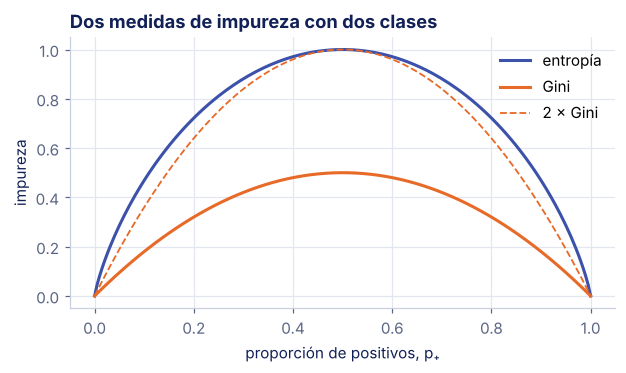

In [23]:
p = np.linspace(0, 1, 201)
with np.errstate(divide="ignore", invalid="ignore"):
    ent = np.nan_to_num(-p * np.log2(p) - (1 - p) * np.log2(1 - p))
gini = 1 - p**2 - (1 - p)**2

fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.plot(p, ent, color=AZUL_MEDIO, linewidth=2, label="entropía")
ax.plot(p, gini, color=NARANJA, linewidth=2, label="Gini")
ax.plot(p, 2 * gini, color=NARANJA, linewidth=1.2, linestyle="--", label="2 × Gini")
ax.set_xlabel("proporción de positivos, p₊")
ax.set_ylabel("impureza")
ax.set_title("Dos medidas de impureza con dos clases")
ax.legend(loc="upper right")
plt.show()

In [24]:
arbol_gini = DecisionTreeClassifier(random_state=0).fit(X_dias, y_dias)     # criterion="gini" por omisión
iguales = export_text(arbol_gini, feature_names=list(X_dias.columns)) == export_text(arbol_sk, feature_names=list(X_dias.columns))
print("¿El mismo árbol que con entropía?", iguales)
print(f"Impureza de la raíz: entropía {entropia(y_dias):.3f}, Gini {1 - (y_dias.value_counts(normalize=True) ** 2).sum():.3f}")

¿El mismo árbol que con entropía? True
Impureza de la raíz: entropía 0.940, Gini 0.459


**Lectura.** Las dos curvas tienen la misma forma: cero en los nodos puros y el máximo con las clases empatadas. Gini vale la mitad que la entropía en el centro, pero casi nunca cambia cuál corte gana, y aquí no lo cambia: el árbol es idéntico. scikit-learn usa Gini por omisión porque no necesita logaritmos.

El mismo árbol, dibujado:

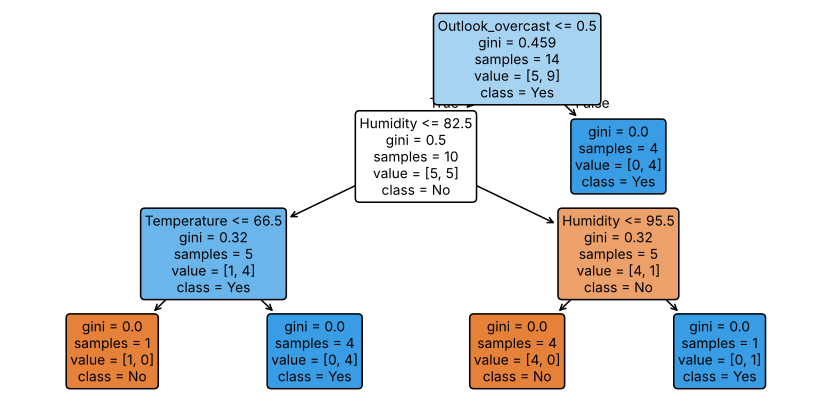

In [25]:
fig, ax = plt.subplots(figsize=(9.5, 4.6))
plot_tree(arbol_gini, feature_names=list(X_dias.columns), class_names=["No", "Yes"], filled=True,
          rounded=True, fontsize=9, ax=ax)
plt.show()

**Lectura.** Cada caja muestra el corte, el Gini del nodo, cuántos días llegan (`samples`) y cuántos hay de cada clase (`value`, primero No y luego Yes). El color indica la clase mayoritaria, y su intensidad, la pureza del nodo.

### La trampa de `LabelEncoder`

Una tentación es convertir cada categoría en un número con `LabelEncoder`, que numera por orden alfabético: overcast = 0, rain = 1, sunny = 2. El árbol no sabe que esos números son etiquetas: los trata como medidas y busca umbrales entre ellos.

In [26]:
def forma(codigos):
    # Tamaño del árbol con Outlook codificado como un solo número, según el diccionario `codigos`.
    X = numerico[ATRIBUTOS].assign(Outlook=numerico["Outlook"].map(codigos),
                                   Wind=(numerico["Wind"] == "weak").astype(int))
    a = DecisionTreeClassifier(random_state=0).fit(X, y_dias)
    return a.get_n_leaves(), a.get_depth()


for nombre, codigos in {"alfabético (LabelEncoder)": {"overcast": 0, "rain": 1, "sunny": 2},
                        "otro orden": {"sunny": 0, "overcast": 1, "rain": 2}}.items():
    n_hojas, profundidad = forma(codigos)
    print(f"{nombre:26s} {codigos} -> {n_hojas} hojas, profundidad {profundidad}")

alfabético (LabelEncoder)  {'overcast': 0, 'rain': 1, 'sunny': 2} -> 5 hojas, profundidad 3
otro orden                 {'sunny': 0, 'overcast': 1, 'rain': 2} -> 7 hojas, profundidad 4


**Lectura.** Los mismos días dan árboles distintos según un orden que nadie eligió. Con el orden alfabético, overcast quedó en un extremo y un solo umbral lo separa; con el otro orden, quedó en medio y hacen falta dos. `LabelEncoder` es para la variable objetivo; para los atributos, *one-hot*.

### Valores faltantes

Desde la versión 1.3, los árboles de scikit-learn aceptan `NaN` (lámina 50): en cada corte aprenden hacia qué rama mandar los ejemplos con el valor faltante. Quitemos la humedad de D1:

In [27]:
X_hueco = X_dias.astype(float)
X_hueco.loc[0, "Humidity"] = np.nan          # D1 sin humedad
arbol_hueco = DecisionTreeClassifier(random_state=0).fit(X_hueco, y_dias)
print(export_text(arbol_hueco, feature_names=list(X_hueco.columns)))

lado = "izquierda (<=)" if arbol_hueco.tree_.missing_go_to_left[0] else "derecha (>)"
print(f"En la raíz, los días sin humedad van a la rama {lado}")
print(f"Predicción para D1: {arbol_hueco.predict(X_hueco.iloc[[0]])[0]} (su clase real: {y_dias.iloc[0]})")

|--- Humidity <= 88.00
|   |--- Temperature <= 66.50
|   |   |--- Outlook_rain <= 0.50
|   |   |   |--- class: True
|   |   |--- Outlook_rain >  0.50
|   |   |   |--- class: False
|   |--- Temperature >  66.50
|   |   |--- class: True
|--- Humidity >  88.00
|   |--- Outlook_sunny <= 0.50
|   |   |--- Wind_weak <= 0.50
|   |   |   |--- Outlook_rain <= 0.50
|   |   |   |   |--- class: True
|   |   |   |--- Outlook_rain >  0.50
|   |   |   |   |--- class: False
|   |   |--- Wind_weak >  0.50
|   |   |   |--- class: True
|   |--- Outlook_sunny >  0.50
|   |   |--- class: False

En la raíz, los días sin humedad van a la rama derecha (>)
Predicción para D1: False (su clase real: False)


**Lectura.** scikit-learn entrena sin quejarse: en cada corte probó mandar a D1 a cada lado y se quedó con el que más reduce la impureza. D1 terminó en la rama de humedad alta, con los otros días soleados y húmedos, y sigue clasificado como No. Pero el árbol cambió entero. Con un solo valor faltante, la primera pregunta ya no es si el día está nublado sino la humedad. Es otra muestra de lo inestable que es un árbol (lámina 51).

---

## 4. El vino: cuánto podar

Con 14 días todo cabe en una pantalla. Con datos reales, el árbol completo deja de ser legible y, sobre todo, se sobreajusta. Volvemos al vino de 3 clases de la sesión 12, con la misma semilla y con los duplicados agrupados: ninguna copia de un vino puede quedar de un lado de la partición y su gemela del otro.

In [28]:
from sklearn.metrics import f1_score

vinos = pd.read_csv("datos/vinos-3clases.csv")
# vinos = pd.read_csv("https://raw.githubusercontent.com/husseinlopez/icd2026/main/datos/vinos-3clases.csv")

X = vinos.drop(columns="calidad")
y = vinos["calidad"]
grupos = pd.util.hash_pandas_object(vinos, index=False)      # filas idénticas, mismo grupo (notebook 12)

p_clase = y.value_counts(normalize=True)
print(f"{len(vinos)} vinos, {grupos.nunique()} distintos")
print(f"Entropía de la raíz: {entropia(y):.3f}   (máximo con 3 clases: log2(3) = {math.log2(3):.3f})")
print(f"Gini de la raíz:     {1 - (p_clase ** 2).sum():.3f}   (máximo con 3 clases: {1 - 3 * (1 / 3) ** 2:.3f})")

1599 vinos, 1359 distintos
Entropía de la raíz: 1.434   (máximo con 3 clases: log2(3) = 1.585)
Gini de la raíz:     0.606   (máximo con 3 clases: 0.667)


**Lectura.** Con tres clases, la entropía pasa de 1: llega a 1.434, cerca de su máximo de 1.585 (lámina 18). Las clases no están empatadas, pero ninguna domina.

### El árbol completo

In [29]:
completo = DecisionTreeClassifier(random_state=0).fit(X, y)
print(f"Hojas: {completo.get_n_leaves()}; profundidad: {completo.get_depth()}")
print(f"F1 macro en los mismos vinos con que se entrenó: {f1_score(y, completo.predict(X), average='macro'):.3f}")

Hojas: 356; profundidad: 20
F1 macro en los mismos vinos con que se entrenó: 1.000


**Lectura.** 356 hojas para 1599 vinos, unos 4.5 vinos por hoja, en 20 niveles. En los vinos con que se entrenó no se equivoca nunca, y eso no dice nada: es la memoria del árbol.

### La curva de validación

La lámina 36 muestra la exactitud contra el tamaño del árbol, en entrenamiento y en datos que no vio. La misma curva con el vino: limitamos la profundidad con `max_depth`, de 1 a 20, y medimos el F1 macro con 10 pliegues agrupados, como en la sección 6 del notebook 12.

In [30]:
from sklearn.model_selection import StratifiedGroupKFold, cross_validate

pliegues = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEMILLA)
filas = []
for profundidad in list(range(1, 21)) + [None]:
    r = cross_validate(DecisionTreeClassifier(max_depth=profundidad, random_state=0), X, y, groups=grupos,
                       cv=pliegues, scoring="f1_macro", return_train_score=True, return_estimator=True)
    filas.append({"max_depth": profundidad if profundidad else "sin límite",
                  "hojas": np.mean([m.get_n_leaves() for m in r["estimator"]]),
                  "entrenamiento": r["train_score"].mean(),
                  "validación": r["test_score"].mean(),
                  "desv. est.": r["test_score"].std()})
curva = pd.DataFrame(filas)
curva.round(3)

,max_depth,hojas,entrenamiento,validación,desv. est.
0,1,2.0,0.411,0.400,0.026
1,2,4.0,0.424,0.412,0.044
2,3,8.0,0.564,0.537,0.042
3,4,15.9,0.629,0.560,0.052
4,5,30.8,0.676,0.569,0.044
5,6,56.0,0.721,0.555,0.051
6,7,89.9,0.781,0.559,0.039
7,8,130.0,0.832,0.544,0.051
8,9,169.7,0.872,0.551,0.040
9,10,204.7,0.908,0.540,0.044


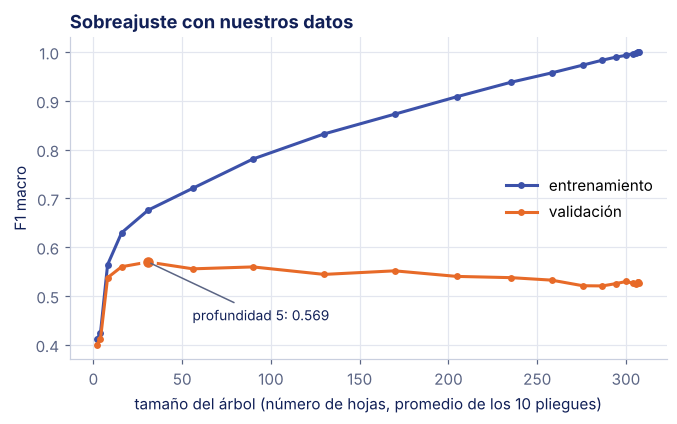

In [31]:
mejor = curva.loc[curva["validación"].idxmax()]

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(curva["hojas"], curva["entrenamiento"], color=AZUL_MEDIO, linewidth=2, marker="o", markersize=3.5, label="entrenamiento")
ax.plot(curva["hojas"], curva["validación"], color=NARANJA, linewidth=2, marker="o", markersize=3.5, label="validación")
ax.scatter(mejor["hojas"], mejor["validación"], s=80, color=NARANJA, edgecolor="white", linewidth=2, zorder=3)
ax.annotate(f"profundidad {mejor['max_depth']}: {mejor['validación']:.3f}", (mejor["hojas"], mejor["validación"]),
            xytext=(mejor["hojas"] + 25, 0.45), color=AZUL_OSCURO, fontsize=9, arrowprops=dict(arrowstyle="-", color=GRIS))
ax.set_xlabel("tamaño del árbol (número de hojas, promedio de los 10 pliegues)")
ax.set_ylabel("F1 macro")
ax.set_title("Sobreajuste con nuestros datos")
ax.legend(loc="center right")
plt.show()

**Lectura.** Es la lámina 36 con datos reales (lámina 37). En entrenamiento, el F1 macro sube con cada nivel hasta 1.00. En validación sube hasta 0.569 con profundidad 5, unas 31 hojas, y después baja despacio hasta 0.526 con el árbol completo. La desviación entre pliegues es de 0.03 a 0.05, así que las profundidades 4 a 7 no se distinguen entre sí. Lo que sí queda claro es que al árbol completo le sobran cientos de hojas.

### Poda por costo-complejidad

La otra forma de controlar el tamaño es crecer el árbol completo y podarlo después (lámina 41). Para cada valor de α, CART busca el subárbol que minimiza

$$R_\alpha(T) = R(T) + \alpha\,|T|$$

donde $R(T)$ es la impureza de las hojas y $|T|$, el número de hojas. Con α = 0 no se poda nada; al subir α, cada hoja cuesta más y el árbol se encoge. `cost_complexity_pruning_path` da los valores de α en los que el árbol cambia:

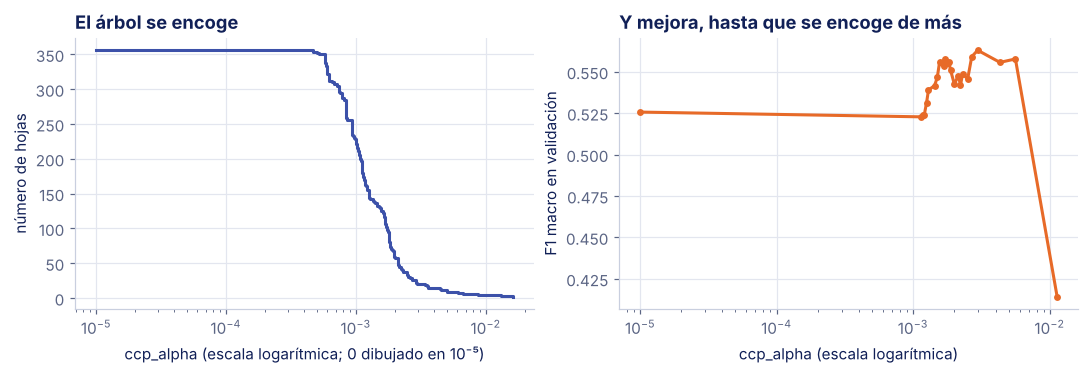

213 valores de α en la trayectoria. El mejor de los 26 probados es α = 0.0030: F1 macro de 0.563 en validación, con 21 hojas al entrenar con todos los vinos
Con α = 0.01 quedan 5 hojas


In [32]:
ruta = completo.cost_complexity_pruning_path(X, y)
alfas = ruta.ccp_alphas[:-1]                  # el último α deja solo la raíz
hojas_alfa = [DecisionTreeClassifier(random_state=0, ccp_alpha=a).fit(X, y).get_n_leaves() for a in alfas]

seleccion = np.unique(np.r_[0.0, np.quantile(alfas, np.linspace(0.5, 0.99, 25))])
validacion_alfa = []
for a in seleccion:
    r = cross_validate(DecisionTreeClassifier(random_state=0, ccp_alpha=a), X, y, groups=grupos,
                       cv=pliegues, scoring="f1_macro")
    validacion_alfa.append(r["test_score"].mean())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.step(np.maximum(alfas, 1e-5), hojas_alfa, where="post", color=AZUL_MEDIO, linewidth=2)
ax1.set_xscale("log")
ax1.set_xlabel("ccp_alpha (escala logarítmica; 0 dibujado en 10⁻⁵)")
ax1.set_ylabel("número de hojas")
ax1.set_title("El árbol se encoge")
ax2.plot(np.maximum(seleccion, 1e-5), validacion_alfa, color=NARANJA, linewidth=2, marker="o", markersize=3.5)
ax2.set_xscale("log")
ax2.set_xlabel("ccp_alpha (escala logarítmica)")
ax2.set_ylabel("F1 macro en validación")
ax2.set_title("Y mejora, hasta que se encoge de más")
plt.tight_layout()
plt.show()

i = int(np.argmax(validacion_alfa))
hojas_mejor = DecisionTreeClassifier(random_state=0, ccp_alpha=seleccion[i]).fit(X, y).get_n_leaves()
print(f"{len(alfas)} valores de α en la trayectoria. El mejor de los {len(seleccion)} probados es α = {seleccion[i]:.4f}: "
      f"F1 macro de {validacion_alfa[i]:.3f} en validación, con {hojas_mejor} hojas al entrenar con todos los vinos")
print(f"Con α = 0.01 quedan {DecisionTreeClassifier(random_state=0, ccp_alpha=0.01).fit(X, y).get_n_leaves()} hojas")

**Lectura.** Con α = 0, el árbol tiene sus 356 hojas; con α = 0.01 le quedan 5. En validación, el F1 macro sube conforme se poda, llega a 0.563 con α = 0.003, que deja 21 hojas, y se desploma cuando el árbol se queda casi sin ramas. Los dos caminos, limitar la profundidad o podar después, llegan a lo mismo: unas 20 o 30 hojas en lugar de más de 300, con un F1 macro de 0.56 a 0.57.

### El protocolo: elegir con validación, medir una vez

La curva eligió la profundidad mirando los 10 pliegues de todos los vinos. Para reportar cuánto rinde el árbol elegido hace falta un conjunto que no haya participado en la elección (sesión 12). El protocolo completo, el de la lámina 42:

1. Apartar 20 % de los vinos para prueba, con los duplicados del mismo lado.
2. Con el 80 % restante, buscar la mejor combinación de hiperparámetros con validación cruzada agrupada: `GridSearchCV`.
3. Reentrenar con todo el 80 % y medir en prueba **una sola vez**.

`StratifiedGroupKFold` no tiene una función para partir una sola vez, pero la primera de sus 5 particiones es justo un 80/20 estratificado que respeta los grupos.

In [33]:
i_entrena, i_prueba = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA).split(X, y, grupos))
X_entrena, X_prueba = X.iloc[i_entrena], X.iloc[i_prueba]
y_entrena, y_prueba = y.iloc[i_entrena], y.iloc[i_prueba]
g_entrena = grupos.iloc[i_entrena]

print(f"Entrenamiento: {len(i_entrena)} vinos; prueba: {len(i_prueba)}")
print(f"Grupos de duplicados repartidos entre los dos lados: {len(set(g_entrena) & set(grupos.iloc[i_prueba]))}")
pd.DataFrame({"entrenamiento": y_entrena.value_counts(normalize=True),
              "prueba": y_prueba.value_counts(normalize=True)}).reindex(CLASES).round(3)

Entrenamiento: 1279 vinos; prueba: 320
Grupos de duplicados repartidos entre los dos lados: 0


,entrenamiento,prueba
calidad,,
baja,0.465,0.466
media,0.399,0.400
alta,0.136,0.134


In [34]:
from sklearn.model_selection import GridSearchCV

rejilla = {"max_depth": [2, 3, 4, 5, 6, 8, 10, None], "min_samples_leaf": [1, 5, 10, 20, 40]}
busqueda = GridSearchCV(DecisionTreeClassifier(random_state=0), rejilla, scoring="f1_macro",
                        cv=StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA))
busqueda.fit(X_entrena, y_entrena, groups=g_entrena)

resultados = pd.DataFrame(busqueda.cv_results_)
print(f"Combinaciones probadas: {len(resultados)}")
print(f"La mejor: {busqueda.best_params_}, con F1 macro de {busqueda.best_score_:.3f} en validación\n")
resultados.sort_values("rank_test_score")[["params", "mean_test_score", "std_test_score"]].head(5).round(3)

Combinaciones probadas: 40
La mejor: {'max_depth': 6, 'min_samples_leaf': 5}, con F1 macro de 0.584 en validación



,params,mean_test_score,std_test_score
21,"{'max_depth': 6, 'min_samples_leaf': 5}",0.584,0.022
22,"{'max_depth': 6, 'min_samples_leaf': 10}",0.584,0.038
20,"{'max_depth': 6, 'min_samples_leaf': 1}",0.582,0.030
32,"{'max_depth': 10, 'min_samples_leaf': 10}",0.581,0.042
27,"{'max_depth': 8, 'min_samples_leaf': 10}",0.577,0.041


**Lectura.** Gana la profundidad 6 con al menos 5 vinos por hoja, pero las tres primeras combinaciones quedan a menos de 0.002 entre sí, muy por debajo de la desviación entre pliegues. No hay que leer demasiado en el ganador: cualquiera de las tres es razonable.

Ahora sí, la prueba, una sola vez. Junto al árbol elegido van el árbol completo y la regresión logística del notebook 12, evaluados igual:

In [35]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

elegido = busqueda.best_estimator_            # GridSearchCV ya lo reentrenó con todo el entrenamiento
completo_e = DecisionTreeClassifier(random_state=0).fit(X_entrena, y_entrena)
logistica = make_pipeline(StandardScaler(), LogisticRegression(C=np.inf, max_iter=5000))
cv_logistica = cross_validate(logistica, X_entrena, y_entrena, groups=g_entrena, scoring="f1_macro",
                              cv=StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA))
logistica.fit(X_entrena, y_entrena)

es_completo = resultados["params"].apply(lambda d: d["max_depth"] is None and d["min_samples_leaf"] == 1)
pd.DataFrame({
    "árbol completo": {"hojas": completo_e.get_n_leaves(),
                       "F1 macro, validación": resultados.loc[es_completo, "mean_test_score"].iloc[0],
                       "F1 macro, prueba": f1_score(y_prueba, completo_e.predict(X_prueba), average="macro")},
    "árbol elegido": {"hojas": elegido.get_n_leaves(),
                      "F1 macro, validación": busqueda.best_score_,
                      "F1 macro, prueba": f1_score(y_prueba, elegido.predict(X_prueba), average="macro")},
    "regresión logística": {"hojas": np.nan,
                            "F1 macro, validación": cv_logistica["test_score"].mean(),
                            "F1 macro, prueba": f1_score(y_prueba, logistica.predict(X_prueba), average="macro")},
}).T.round(3)

,hojas,"F1 macro, validación","F1 macro, prueba"
árbol completo,274.0,0.551,0.484
árbol elegido,55.0,0.584,0.551
regresión logística,NaN,0.562,0.573


**Lectura.** El árbol elegido tiene 55 hojas en lugar de 274 y en prueba saca 0.551, contra 0.484 del árbol completo: la poda mejoró justo lo que importa. Pero su 0.584 de validación prometía más. No es mala suerte. Es el máximo de 40 combinaciones, y el máximo de varias estimaciones ruidosas es optimista; por eso la prueba se usa una sola vez, al final, y nunca para elegir. La logística, que no tiene nada que ajustar, queda en 0.573: el árbol podado se le acerca, pero no la supera.

### Leer el árbol elegido

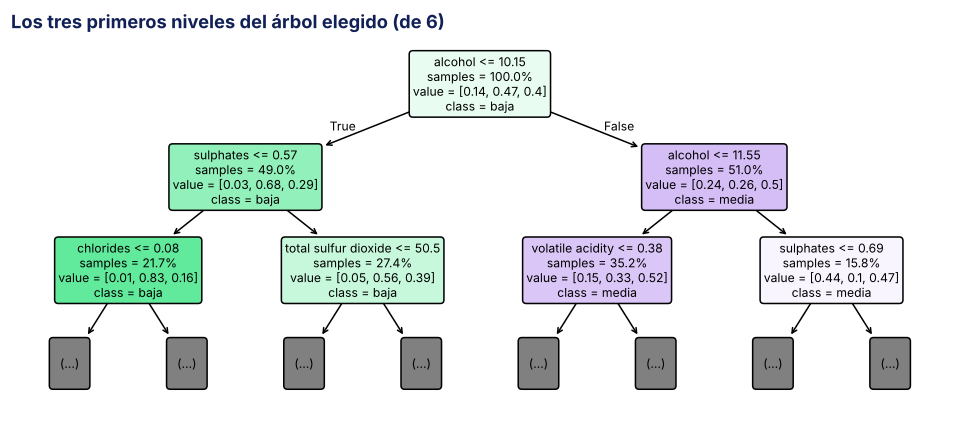

In [36]:
fig, ax = plt.subplots(figsize=(11, 4.4))
plot_tree(elegido, max_depth=2, feature_names=list(X.columns), class_names=list(elegido.classes_), filled=True,
          rounded=True, impurity=False, proportion=True, precision=2, fontsize=8, ax=ax)
ax.set_title("Los tres primeros niveles del árbol elegido (de 6)")
plt.show()

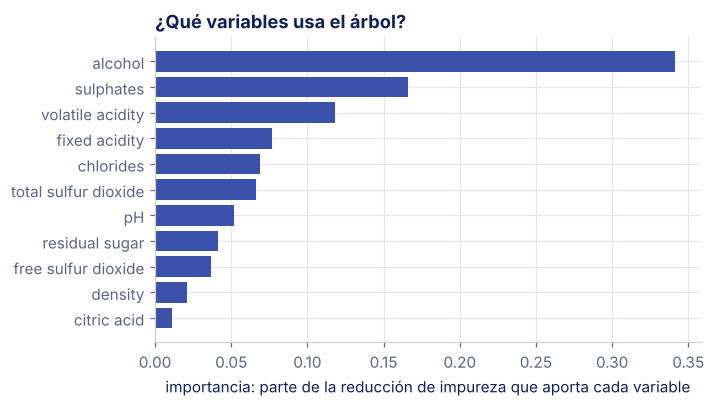

,importancia
alcohol,0.341
sulphates,0.166
volatile acidity,0.118
fixed acidity,0.077
chlorides,0.069


In [37]:
importancia = pd.Series(elegido.feature_importances_, index=X.columns).sort_values()

fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.barh(importancia.index, importancia.values, color=AZUL_MEDIO)
ax.set_xlabel("importancia: parte de la reducción de impureza que aporta cada variable")
ax.set_title("¿Qué variables usa el árbol?")
plt.show()
importancia.sort_values(ascending=False).head(5).round(3).to_frame("importancia")

**Lectura.** La primera pregunta del árbol es el alcohol, y el alcohol aporta un tercio de toda la reducción de impureza (0.341). Le siguen los sulfatos (0.166) y la acidez volátil (0.118). El alcohol y los sulfatos también encabezaban las razones de momios de la sesión 11. Pero la importancia de un árbol no tiene signo ni intervalo, y depende de la muestra, como muestra el siguiente experimento.

### Un árbol es inestable

Entrenamos dos modelos con mitades distintas del entrenamiento, con los duplicados juntos, y contamos en cuántos vinos de prueba dan clases distintas. Repetimos 20 veces. Si el método es estable, los dos modelos deberían coincidir casi siempre (lámina 51).

In [38]:
rng = np.random.default_rng(SEMILLA)
unicos = pd.unique(g_entrena)
modelos = {
    "árbol completo": lambda: DecisionTreeClassifier(random_state=0),
    "árbol elegido": lambda: DecisionTreeClassifier(random_state=0, **busqueda.best_params_),
    "regresión logística": lambda: make_pipeline(StandardScaler(), LogisticRegression(C=np.inf, max_iter=5000)),
}
desacuerdo = {nombre: [] for nombre in modelos}
raices = Counter()
for _ in range(20):
    mitad = set(rng.permutation(unicos)[: len(unicos) // 2])
    en_mitad = g_entrena.isin(mitad).to_numpy()
    for nombre, crear in modelos.items():
        a = crear().fit(X_entrena[en_mitad], y_entrena[en_mitad])
        b = crear().fit(X_entrena[~en_mitad], y_entrena[~en_mitad])
        desacuerdo[nombre].append((a.predict(X_prueba) != b.predict(X_prueba)).mean())
        if nombre == "árbol completo":
            raices.update(X.columns[m.tree_.feature[0]] for m in (a, b))

resumen = pd.DataFrame({n: {"promedio": np.mean(v), "mínimo": np.min(v), "máximo": np.max(v)}
                        for n, v in desacuerdo.items()}).T
print("Raíz de los 40 árboles completos:", dict(raices))
(resumen * 100).round(1).astype(str) + " %"

Raíz de los 40 árboles completos: {'alcohol': 40}


,promedio,mínimo,máximo
árbol completo,48.1 %,42.8 %,52.5 %
árbol elegido,42.3 %,32.2 %,54.7 %
regresión logística,19.1 %,13.4 %,26.6 %


**Lectura.** Dos árboles completos entrenados con mitades distintas clasifican distinto 48 % de los vinos de prueba: casi uno de cada dos. Podados, 42 %; las logísticas, 19 %. Los 40 árboles completos tienen el alcohol en la raíz, así que lo que cambia está abajo, donde cada nodo decide con menos vinos. Esa variación es el precio de un modelo tan flexible, y es lo que ataca Random Forest en la sesión 18: promediar muchos árboles entrenados con muestras distintas.

---

Las sesiones 14 a 16 abren las otras cajas negras de la sesión 12: Naive Bayes, el vecino más cercano y las máquinas de soporte vectorial. Cada una tiene sus propios hiperparámetros, pero el protocolo es el de esta sección: elegir con validación cruzada agrupada dentro del entrenamiento y medir en prueba una sola vez. Es el que pedirá la práctica de la unidad.

---

### Declaración de uso de IA generativa

Este notebook fue elaborado con apoyo de Claude (Anthropic) para estructurar el contenido a partir de las diapositivas de la sesión, redactar el texto explicativo y preparar los conjuntos de datos de ejemplo. El diseño pedagógico, la selección de temas y la revisión final son responsabilidad del titular del curso.

### Referencias

- Mitchell, T. M. (1997). *Machine Learning*, capítulo 3: Decision Tree Learning. McGraw-Hill.
- Quinlan, J. R. (1986). Induction of decision trees. *Machine Learning*, 1(1), 81-106.
- Quinlan, J. R. (1993). *C4.5: Programs for Machine Learning*. Morgan Kaufmann.
- Breiman, L., Friedman, J. H., Olshen, R. A., & Stone, C. J. (1984). *Classification and Regression Trees*. Wadsworth.
- VanderPlas, J. (2022). *Python Data Science Handbook*, 2a ed. O'Reilly. [Capítulo 44: In-Depth: Decision Trees and Random Forests](https://jakevdp.github.io/PythonDataScienceHandbook/05.08-random-forests.html)
- Witten, I. H., Frank, E., Hall, M. A., & Pal, C. J. (2016). *Data Mining: Practical Machine Learning Tools and Techniques*, 4a ed. Morgan Kaufmann. (El libro de Weka y de J48.)
- Cortez, P., Cerdeira, A., Almeida, F., Matos, T., & Reis, J. (2009). Modeling wine preferences by data mining from physicochemical properties. *Decision Support Systems*, 47(4), 547-553.
- [scikit-learn: árboles de decisión](https://scikit-learn.org/stable/modules/tree.html) · [DecisionTreeClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html) · [Poda por costo-complejidad](https://scikit-learn.org/stable/auto_examples/tree/plot_cost_complexity_pruning.html) · [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)